# Workshop 3 Data visualisation
MM311 | Two hours | Source sections 4.1–4.7

Run the book examples, make a small change, then explain the result. Keep both CSV files beside this notebook. Save your own copy. The examples retain the original values and random seeds; minor layout and compatibility fixes are explained in the workbook. Starbucks is a historical February 2017 snapshot according to the supplied chapter and includes subsidiary brands.

**Before class:** use an environment with NumPy, pandas, Matplotlib (3.10 or later), Seaborn (0.13 or later) and Basemap. See SETUP.docx. The complete notebook requires Basemap; do not skip failed imports silently.

**4.1 Imports and display | 0–8 minutes.** Installation adds packages to an environment; imports load them into a new kernel. Static output is sufficient. The helper saves and displays every example; it is provided infrastructure, not a learning objective. A starter notebook that runs is still incomplete until you do its tasks.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
sns.set_theme(style='darkgrid')
output_dir = Path('results')
output_dir.mkdir(exist_ok=True)
print('Python', sys.version.split()[0], 'pandas', pd.__version__)
print('NumPy', np.__version__, 'Matplotlib', matplotlib.__version__, 'Seaborn', sns.__version__)
print('Working folder:', Path.cwd())

def finish(fig, name):
    fig.savefig(output_dir / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)

Python 3.12.14 pandas 3.0.6
NumPy 2.3.5 Matplotlib 3.10.9 Seaborn 0.13.2
Working folder: [workshop folder]


**Task:** change the theme to ticks, run the next chart, then return to darkgrid. Which features change? The five source themes are darkgrid, whitegrid, dark, white and ticks.

## 1 A single Figure and Axes
Source 4.2 | 8–13 min

Run the worked example below.

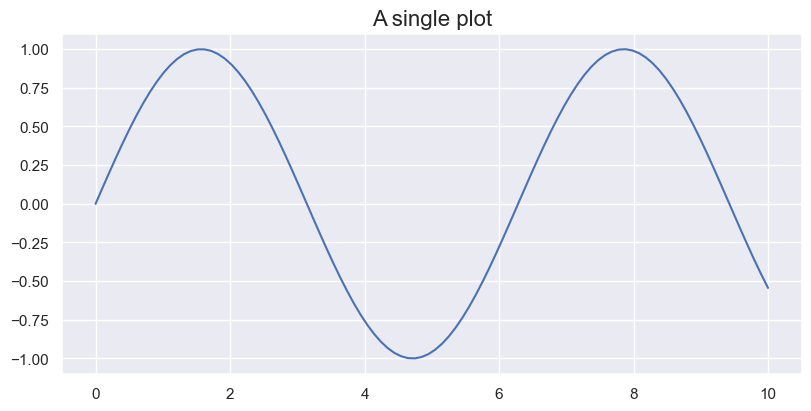

In [2]:
x = np.linspace(0, 10, 100)
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.plot(x, np.sin(x))
ax.set_title("A single plot", fontsize=16)
finish(fig, "single")

### Your task
Add labels x and sin(x), and change the title. Identify the Figure and the Axes.

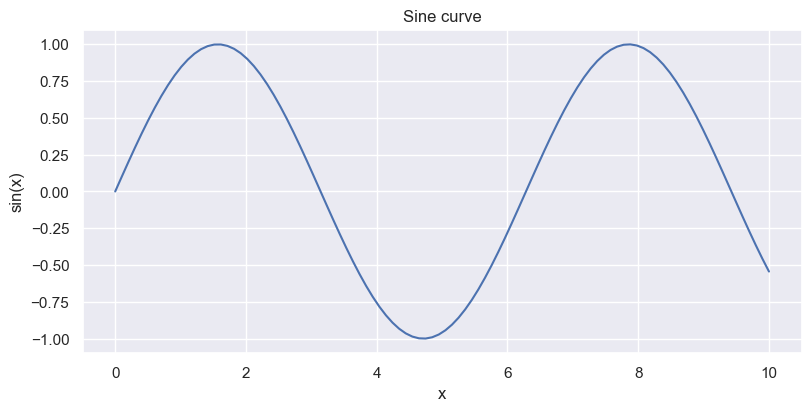

In [3]:
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.plot(x, np.sin(x))
ax.set(xlabel="x", ylabel="sin(x)", title="Sine curve")
finish(fig, "task_single")

**Tutor answer:** Figure is the whole canvas; Axes is the plotting area. These are mathematical sample values, not observed business demand.

## 2 Two vertically stacked plots
Source 4.2 | 13–17 min

Run the worked example below.

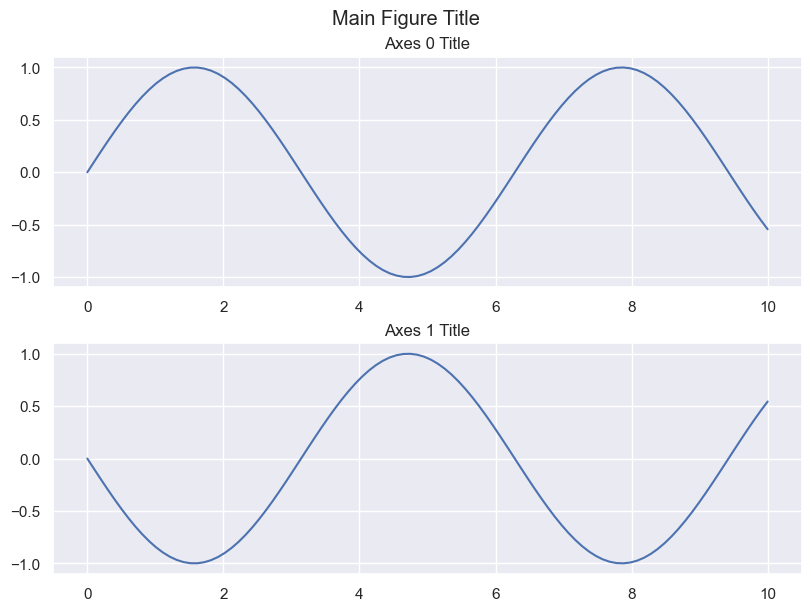

In [4]:
fig, axs = plt.subplots(2, figsize=(8, 6), layout="constrained")
axs[0].plot(x, np.sin(x))
axs[1].plot(x, -np.sin(x))
fig.suptitle("Main Figure Title")
axs[0].set_title("Axes 0 Title")
axs[1].set_title("Axes 1 Title")
finish(fig, "stacked")

### Your task
Change the lower title to Negative sine. Which index selects that Axes?

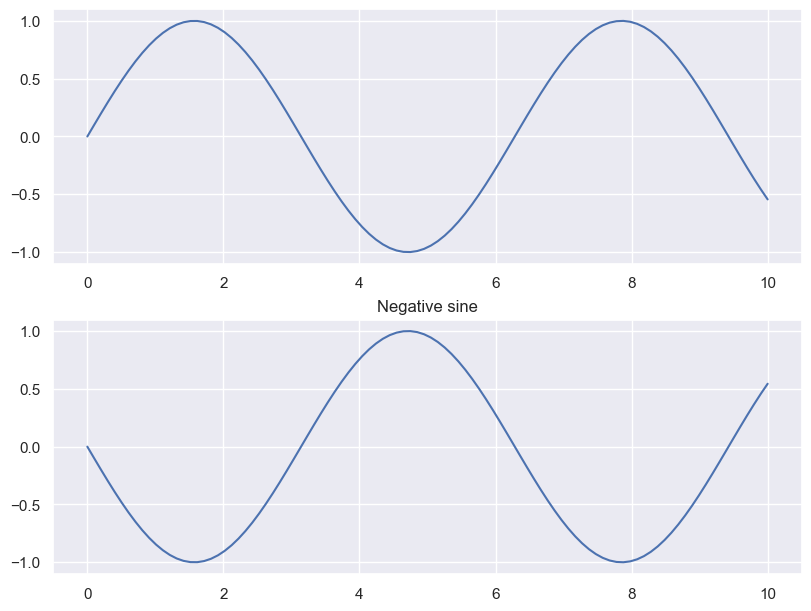

In [5]:
fig, axs = plt.subplots(2, figsize=(8, 6), layout="constrained")
axs[0].plot(x, np.sin(x)); axs[1].plot(x, -np.sin(x))
axs[1].set_title("Negative sine")
finish(fig, "task_stacked")

**Tutor answer:** axs[1] selects the lower Axes. With one column the returned collection is one-dimensional.

## 3 A two by two subplot grid
Source 4.2 | 17–21 min

Run the worked example below.

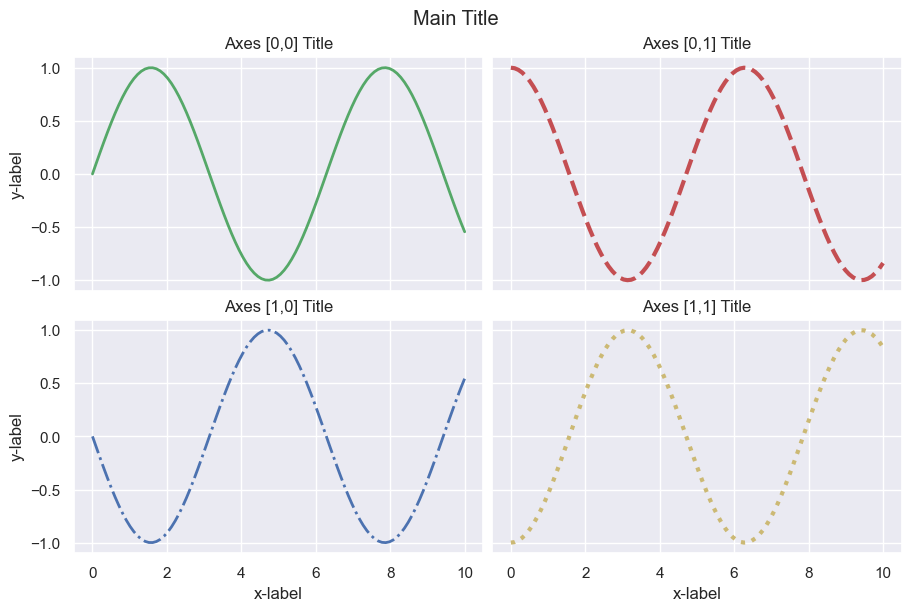

In [6]:
fig, axs = plt.subplots(2, 2, figsize=(9, 6), layout="constrained")
fig.suptitle("Main Title")
axs[0, 0].plot(x, np.sin(x), 'g', linewidth=2)
axs[0, 1].plot(x, np.cos(x), '--r', linewidth=3)
axs[1, 0].plot(x, -np.sin(x), '-.b', linewidth=2)
axs[1, 1].plot(x, -np.cos(x), ':y', linewidth=3)
for row in range(2):
    for col in range(2):
        axs[row, col].set_title(f"Axes [{row},{col}] Title")
for ax in axs.flat:
    ax.set(xlabel="x-label", ylabel="y-label")
    ax.label_outer()
finish(fig, "grid")

### Your task
Locate axs[1, 1]. Explain what label_outer() hides and what axs.flat does.

In [7]:
# Discuss using the worked plot.

**Tutor answer:** [1,1] is bottom-right. flat iterates through all four Axes. label_outer hides inner axis labels and tick labels; it does not remove tick marks by default.

## 4 Shared axes and grid spacing
Source 4.2 | 21–25 min

Run the worked example below.

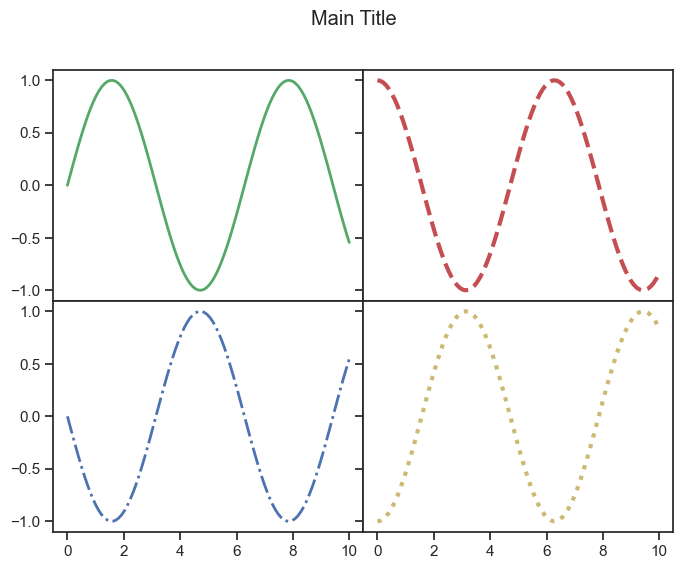

In [8]:
sns.set_theme(style="ticks")
fig, axs = plt.subplots(2, 2, figsize=(8, 6), sharex=True, sharey=True,
                        gridspec_kw={"hspace": 0, "wspace": 0})
(ax1, ax2), (ax3, ax4) = axs
fig.suptitle("Main Title")
ax1.plot(x, np.sin(x), 'g', linewidth=2)
ax2.plot(x, np.cos(x), '--r', linewidth=3)
ax3.plot(x, -np.sin(x), '-.b', linewidth=2)
ax4.plot(x, -np.cos(x), ':y', linewidth=3)
finish(fig, "shared")

### Your task
Explain the effects of sharex, sharey, hspace and wspace. Predict what happens if spacing becomes 0.3.

In [9]:
# Discuss using the worked plot.

**Tutor answer:** Shared axes link scales; the zero spacing makes panels touch. Positive spacing separates them. Keep individual titles away from touching boundaries.

## 5 Adding Axes to a Figure
Source 4.2 | 25–28 min

Run the worked example below.

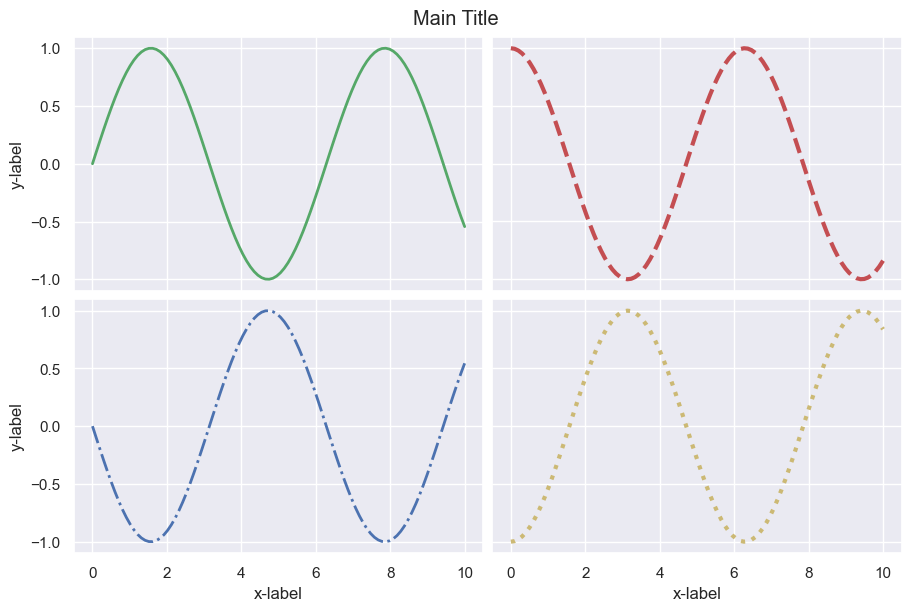

In [10]:
sns.set_theme(style="darkgrid")
fig = plt.figure(figsize=(9, 6), layout="constrained")
fig.suptitle("Main Title")
ax1 = fig.add_subplot(221)
ax2 = fig.add_subplot(2, 2, 2)
ax3 = fig.add_subplot(2, 2, 3)
ax4 = fig.add_subplot(2, 2, 4)
ax1.plot(x, np.sin(x), 'g', linewidth=2)
ax2.plot(x, np.cos(x), '--r', linewidth=3)
ax3.plot(x, -np.sin(x), '-.b', linewidth=2)
ax4.plot(x, -np.cos(x), ':y', linewidth=3)
for ax in fig.get_axes():
    ax.set(xlabel="x-label", ylabel="y-label")
    ax.label_outer()
finish(fig, "addsubplot")

### Your task
Tutor demonstration: compare add_subplot(221) with add_subplot(2, 2, 1). Read the alternative add_axes pattern below.

In [11]:
# No extra coding required.

**Tutor answer:** Both specify the first panel in a 2 by 2 grid. add_axes([left,bottom,width,height]) instead uses Figure-relative fractions for an arbitrary layout. Use subplots for regular grids.

## 6 Formatting four shifted sine curves
Source 4.3 | 28–38 min

Run the worked example below.

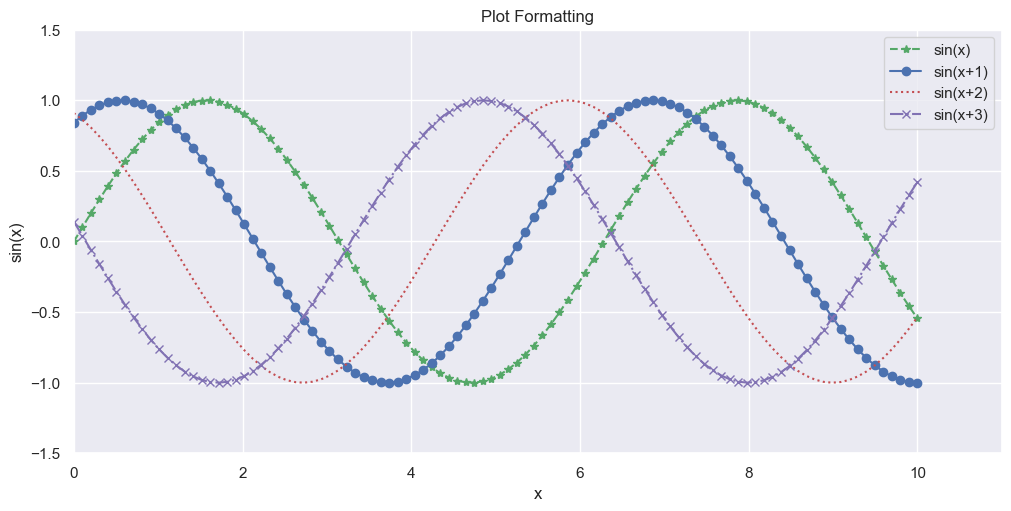

In [12]:
fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
ax.plot(x, np.sin(x), '*--g', label='sin(x)')
ax.plot(x, np.sin(x+1), 'o-b', label='sin(x+1)')
ax.plot(x, np.sin(x+2), ':r', label='sin(x+2)')
ax.plot(x, np.sin(x+3), 'x-.m', label='sin(x+3)')
ax.set(xlim=(0, 11), ylim=(-1.5, 1.5), xlabel='x',
       ylabel='sin(x)', title='Plot Formatting')
ax.legend()
finish(fig, "format")

### Your task
Copy the example and change one marker, one line style and the legend position. Explain *--g.

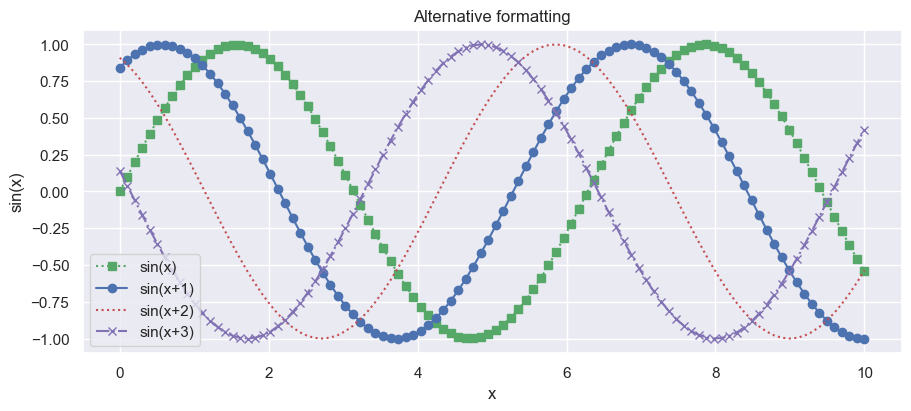

In [13]:
fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
ax.plot(x, np.sin(x), 's:g', label='sin(x)')
ax.plot(x, np.sin(x+1), 'o-b', label='sin(x+1)')
ax.plot(x, np.sin(x+2), ':r', label='sin(x+2)')
ax.plot(x, np.sin(x+3), 'x-.m', label='sin(x+3)')
ax.set(xlabel='x', ylabel='sin(x)', title='Alternative formatting')
ax.legend(loc='lower left')
finish(fig, "task_format")

**Tutor answer:** * is a star marker, -- a dashed line and g green. Different line and marker styles help distinguish curves without relying on colour alone.

## 7 Scatter plot with size and colour
Source 4.4 | 38–44 min

Run the worked example below.

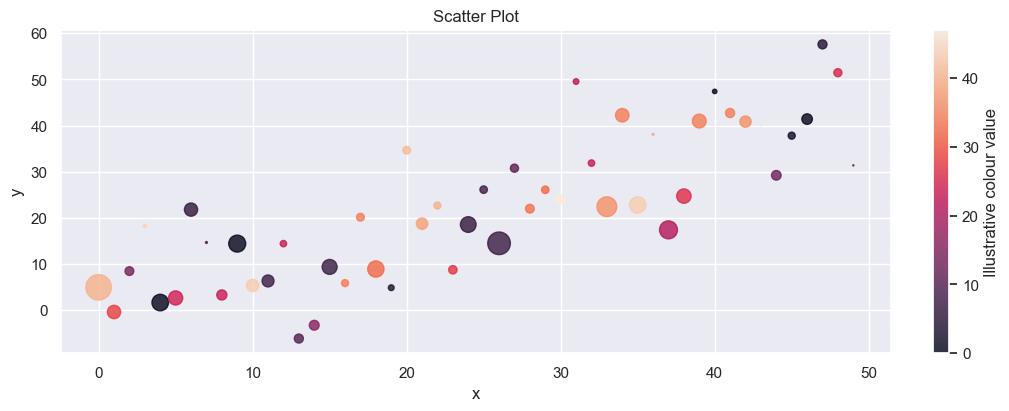

In [14]:
rng = np.random.RandomState(42)
scatter_x = np.arange(50)
scatter_y = scatter_x + 10 * rng.randn(50)
colour = rng.randint(0, 50, 50)
size = np.abs(rng.randn(50)) * 100
fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
points = ax.scatter(scatter_x, scatter_y, c=colour, s=size, alpha=0.8)
ax.set(xlabel='x', ylabel='y', title='Scatter Plot')
fig.colorbar(points, ax=ax, label='Illustrative colour value')
finish(fig, "scatter")

### Your task
Change alpha to 0.4. Explain what position, colour and marker size represent in this example.

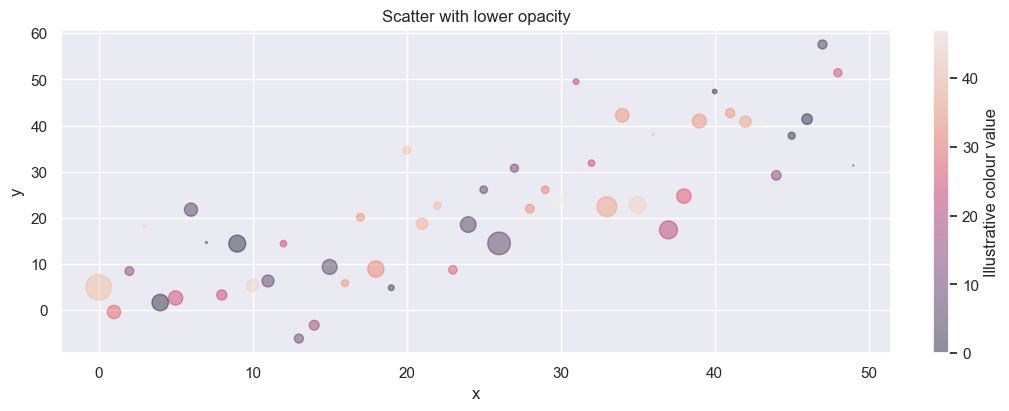

In [15]:
fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
points = ax.scatter(scatter_x, scatter_y, c=colour, s=size, alpha=0.4)
ax.set(xlabel='x', ylabel='y', title='Scatter with lower opacity')
fig.colorbar(points, ax=ax, label='Illustrative colour value')
finish(fig, "task_scatter")

**Tutor answer:** x and y locate each point. c controls colour and s controls marker area in points squared. Lower alpha makes marks more transparent. The extra encodings are random teaching values, not business measures.

## 8 Product cost and profit bars
Source 4.4 | 44–50 min

Run the worked example below.

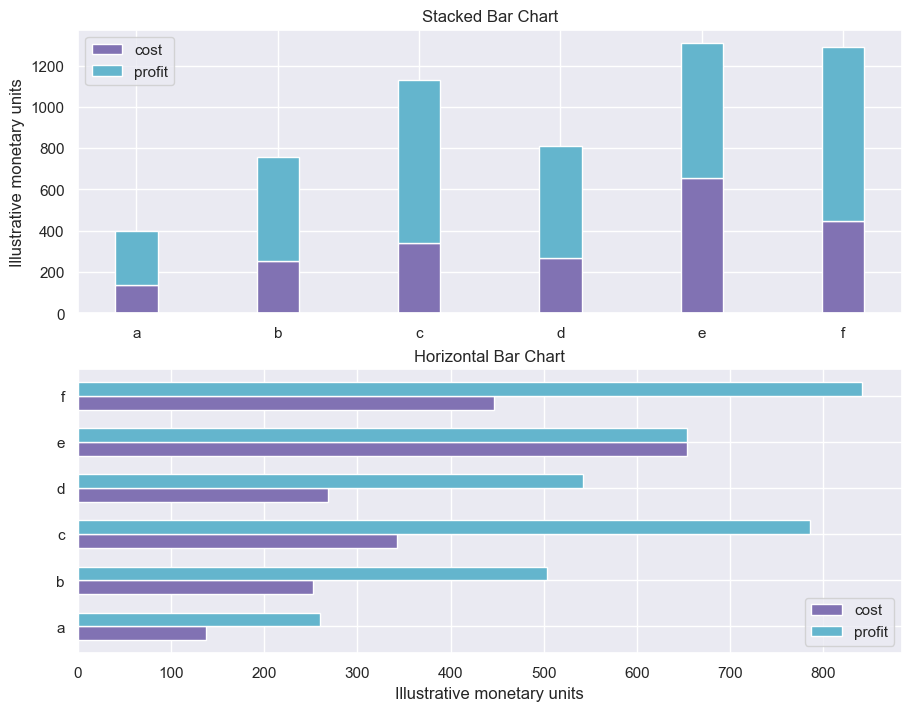

In [16]:
ID = ('a', 'b', 'c', 'd', 'e', 'f')
cost = (138, 252, 342, 269, 654, 447)
profit = (260, 504, 786, 542, 654, 842)
positions = np.arange(6)
width = 0.3
fig, (ax0, ax1) = plt.subplots(2, figsize=(9, 7), layout="constrained")
ax0.bar(positions, cost, width, color='m', label='cost')
ax0.bar(positions, profit, width, bottom=cost, color='c', label='profit')
ax0.set(xticks=positions, xticklabels=ID, title='Stacked Bar Chart',
        ylabel='Illustrative monetary units')
ax0.legend()
ax1.barh(positions, cost, width, color='m', label='cost')
ax1.barh(positions+width, profit, width, color='c', label='profit')
ax1.set(yticks=positions+width/2, yticklabels=ID, title='Horizontal Bar Chart',
        xlabel='Illustrative monetary units')
ax1.legend()
finish(fig, "bars")

### Your task
Identify the highest profit. Explain stacked height versus profit-to-cost ratio. Which chart makes profits easier to compare?

In [17]:
highest = int(np.argmax(profit))
print(ID[highest], profit[highest])
print("Profit-to-cost ratios:", np.round(np.array(profit)/np.array(cost), 2))

f 842
Profit-to-cost ratios: [1.88 2.   2.3  2.01 1.   1.88]


**Tutor answer:** Product f has profit 842. A stacked bar is cost plus profit, not a ratio. Separate bars share a common baseline for easier comparison. Currency is unspecified in the book.

## 9 Four histogram styles
Source 4.4 | 50–56 min

Run the worked example below.

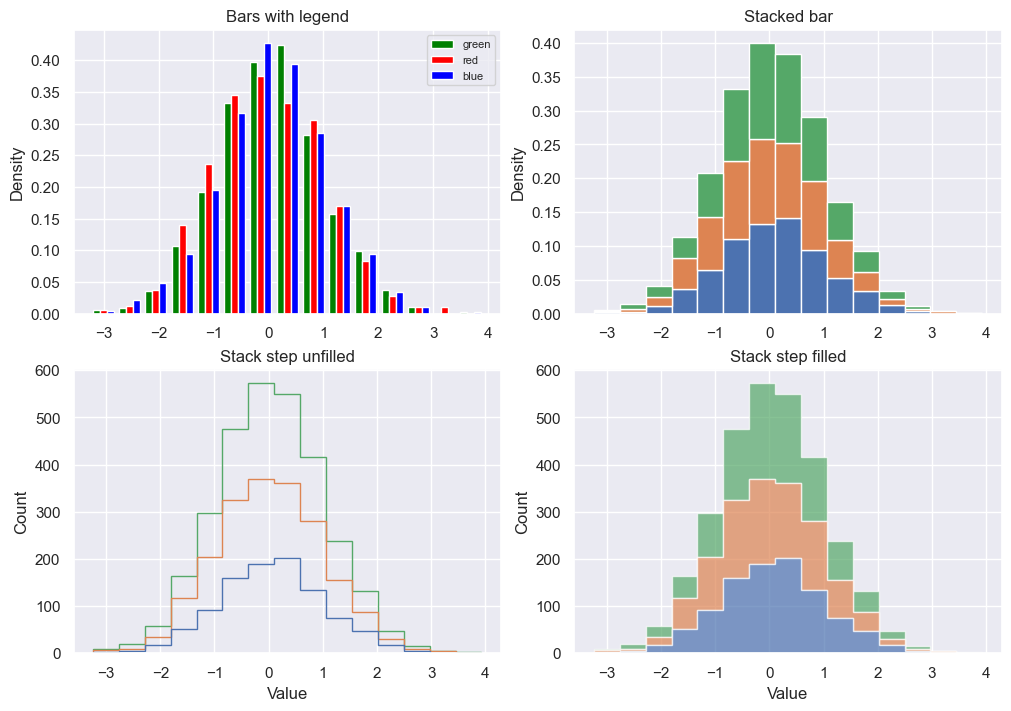

In [18]:
rng = np.random.RandomState(42)
hist_data = rng.randn(1000, 3)
colours = ['green', 'red', 'blue']
n_bins = 15
fig, axs = plt.subplots(2, 2, figsize=(10, 7), layout="constrained")
ax0, ax1, ax2, ax3 = axs.flatten()
ax0.hist(hist_data, n_bins, density=True, color=colours, label=colours)
ax0.legend(fontsize=8); ax0.set(title='Bars with legend', ylabel='Density')
ax1.hist(hist_data, bins=n_bins, density=True, histtype='barstacked')
ax1.set(title='Stacked bar', ylabel='Density')
ax2.hist(hist_data, n_bins, histtype='step', stacked=True)
ax2.set(title='Stack step unfilled', ylabel='Count', xlabel='Value')
ax3.hist(hist_data, n_bins, histtype='stepfilled', alpha=0.7, stacked=True)
ax3.set(title='Stack step filled', ylabel='Count', xlabel='Value')
finish(fig, "hist")

### Your task
Compare 10 and 30 bins for the first sample. Distinguish count from density.

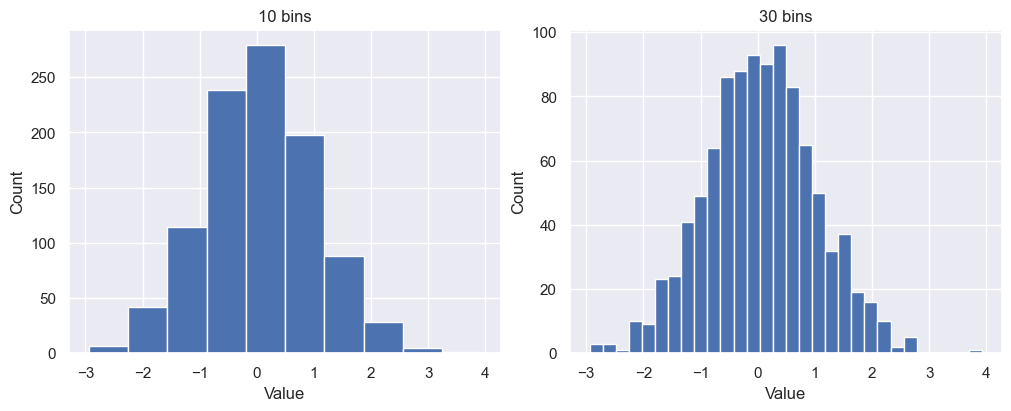

In [19]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
for ax, bins in zip(axs, [10, 30]):
    ax.hist(hist_data[:, 0], bins=bins)
    ax.set(title=f'{bins} bins', xlabel='Value', ylabel='Count')
finish(fig, "task_hist")

**Tutor answer:** More bins show finer variation but can look less smooth. Counts are observations per bin; density rescales area. In the book top panels use density and bottom panels use counts, so their heights are not directly comparable.

## 10 Product shares as pie charts
Source 4.4 | 56–62 min

Run the worked example below.

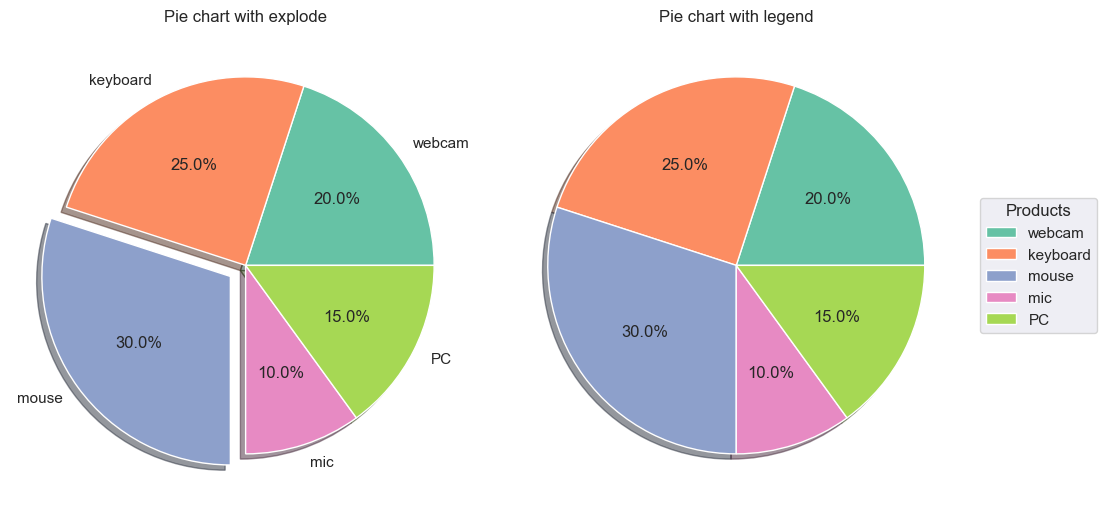

In [20]:
product = ['webcam', 'keyboard', 'mouse', 'mic', 'PC']
pct = [20, 25, 30, 10, 15]
explode = (0, 0, 0.1, 0, 0)
colours = plt.get_cmap('Set2')(np.arange(5))
fig, axs = plt.subplots(1, 2, figsize=(11, 5), layout="constrained")
axs[0].pie(pct, explode=explode, colors=colours, labels=product,
           autopct='%1.1f%%', shadow=True)
axs[0].set_title('Pie chart with explode')
wedges, _, _ = axs[1].pie(pct, colors=colours, autopct='%1.1f%%', shadow=True)
axs[1].set_title('Pie chart with legend')
axs[1].legend(wedges, product, title='Products', loc='center left',
              bbox_to_anchor=(1, 0.5))
finish(fig, "pie")

### Your task
Remove the explosion and shadow in a new chart. Which product has the largest share, and do values add to 100?

Total: 100


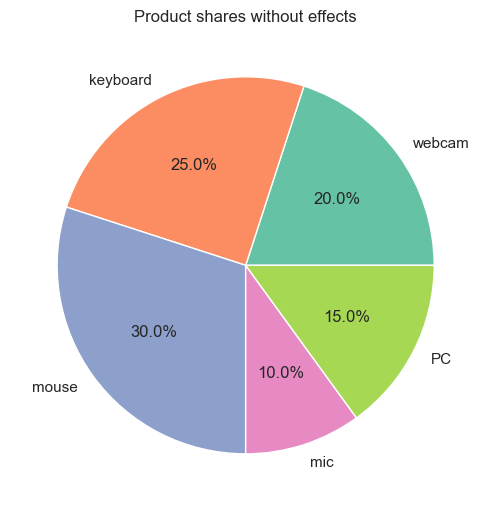

In [21]:
print("Total:", sum(pct))
fig, ax = plt.subplots(figsize=(6, 5), layout="constrained")
ax.pie(pct, labels=product, colors=colours, autopct='%1.1f%%')
ax.set_title('Product shares without effects')
finish(fig, "task_pie")

**Tutor answer:** The values sum to 100 and mouse has 30%. The values are illustrative shares, not Starbucks sales. Explosion and shadow are formatting effects; they do not change data.

## 11 Four boxplot variants
Source 4.4 | 62–68 min

Run the worked example below.

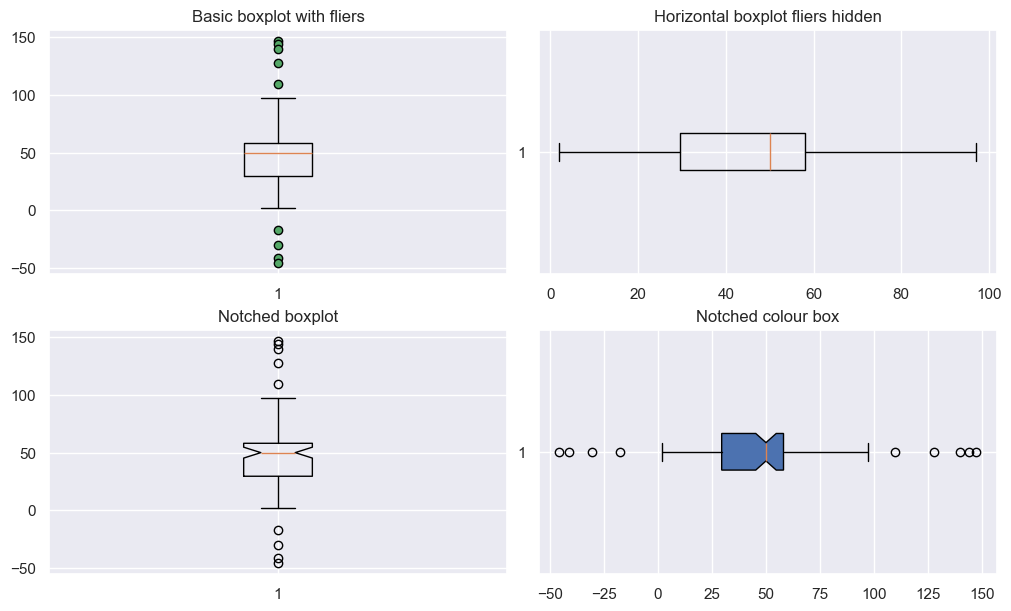

In [22]:
rng = np.random.RandomState(42)
spread = rng.rand(50) * 100
centre = np.ones(30) * 50
flier_high = rng.rand(5) * 100 + 50
flier_low = rng.rand(5) * 100 - 50
box_data = np.concatenate((spread, centre, flier_high, flier_low))
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(10, 6), layout="constrained")
ax1.boxplot(box_data, flierprops={'markerfacecolor': 'g'})
ax1.set_title('Basic boxplot with fliers')
ax2.boxplot(box_data, orientation='horizontal', showfliers=False)
ax2.set_title('Horizontal boxplot fliers hidden')
ax3.boxplot(box_data, notch=True)
ax3.set_title('Notched boxplot')
ax4.boxplot(box_data, notch=True, orientation='horizontal', patch_artist=True)
ax4.set_title('Notched colour box')
finish(fig, "box")

### Your task
Calculate the quartiles and IQR. Does hiding fliers delete observations? Are whiskers always the minimum and maximum?

In [23]:
q1, median, q3 = np.quantile(box_data, [0.25, 0.5, 0.75])
iqr = q3 - q1
print("Q1, median, Q3:", q1, median, q3)
print("Fences:", q1-1.5*iqr, q3+1.5*iqr)
print("Observations:", len(box_data))

Q1, median, Q3: 29.516904714129804 50.0 58.09884964823517
Fences: -13.356012687028251 100.97176704939324
Observations: 90


**Tutor answer:** There are 90 observations and median 50. Hiding fliers only changes display. Default whiskers end at the furthest observations within the 1.5 IQR fences. Fliers are not automatically errors, and a boxplot alone does not establish normality.

## 12 Iris pairplot
Source 4.5 | 68–75 min

Run the worked example below.

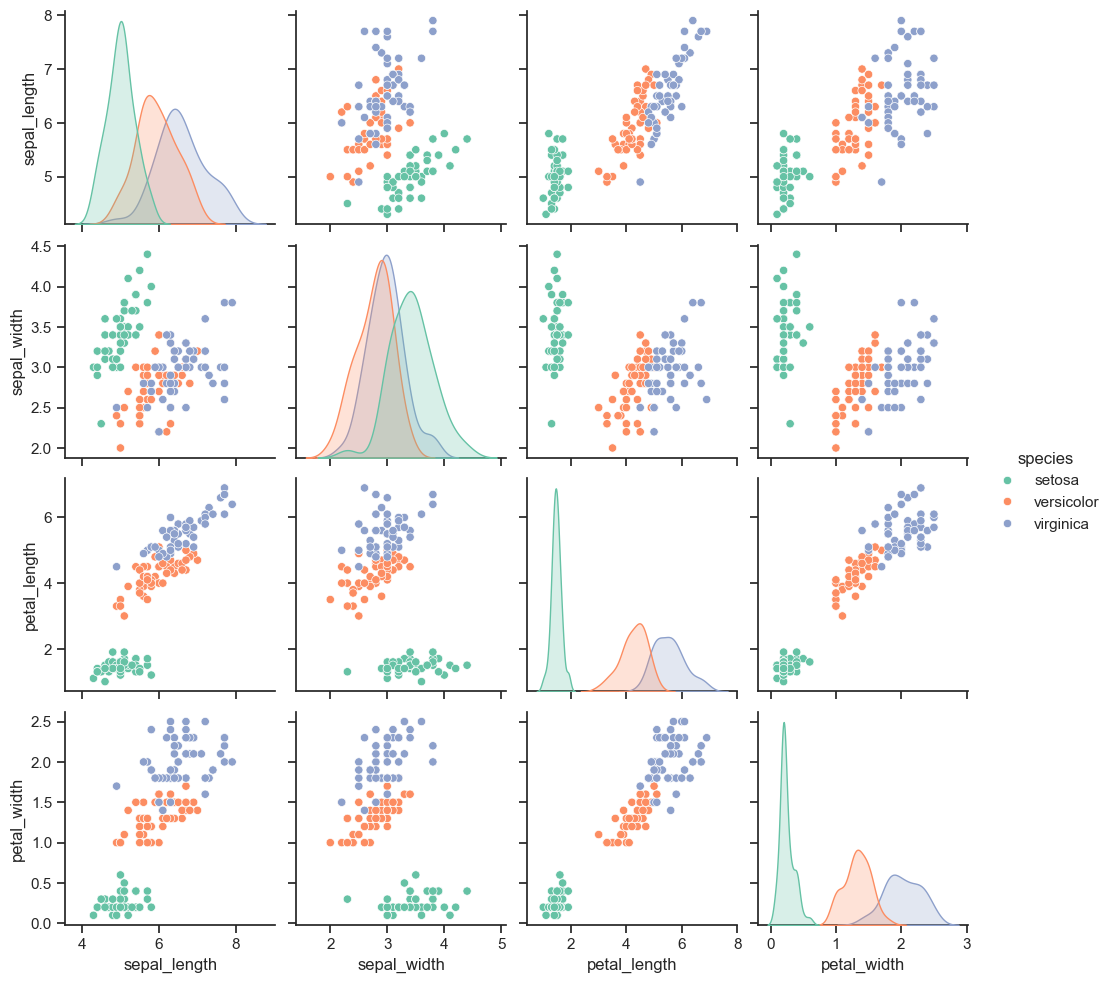

In [24]:
sns.set_theme(style='ticks')
# Book: iris = sns.load_dataset('iris')
# The same Seaborn sample is supplied locally for offline class use.
iris = pd.read_csv('iris.csv')
g = sns.pairplot(iris, hue='species', palette='Set2')
finish(g.figure, "pair")

### Your task
Read one off-diagonal panel and one diagonal panel. Which measurements help distinguish species?

In [25]:
# Explain using the pairplot.

**Tutor answer:** Off-diagonal panels show relationships; diagonal panels show distributions. Petal length and width are useful for separating groups, especially setosa. Hue shows known species labels; the plot is not a trained classifier.

## 13 A masked correlation heatmap
Source 4.5 | 75–83 min

Run the worked example below.

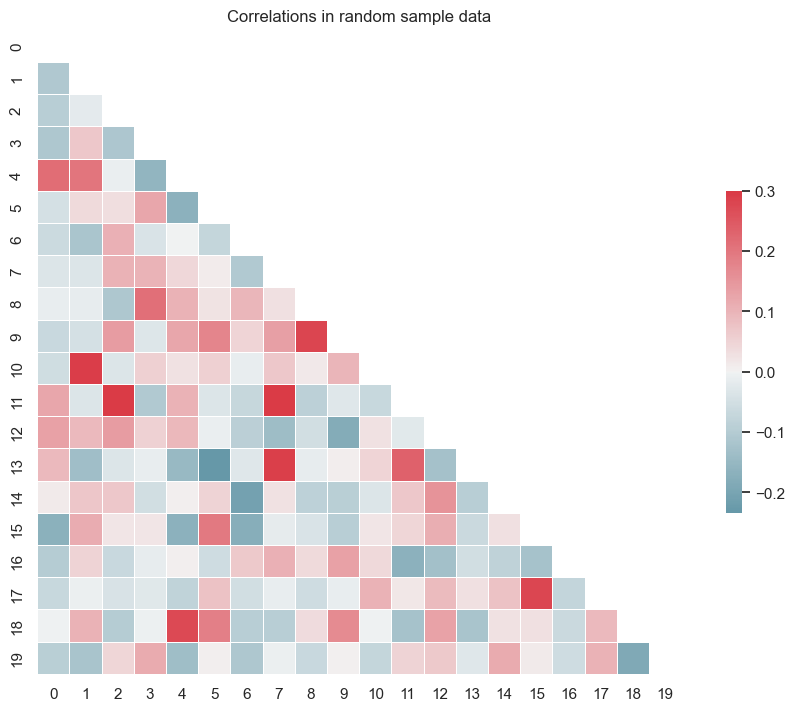

In [26]:
sns.set_theme(style='white')
rng = np.random.RandomState(46)
random_df = pd.DataFrame(rng.normal(size=(100, 20)), columns=np.arange(20))
corr = random_df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(10, 7), layout="constrained")
cmap = sns.diverging_palette(220, 10, as_cmap=True)
sns.heatmap(corr, mask=mask, cmap=cmap, vmax=0.3, center=0,
            square=True, linewidths=0.5, cbar_kws={'shrink': 0.5}, ax=ax)
ax.set_title('Correlations in random sample data')
finish(fig, "heatmap")

### Your task
Repeat with vmin=-1 and vmax=1. Explain the mask, colour scale and why coloured cells do not establish causation.

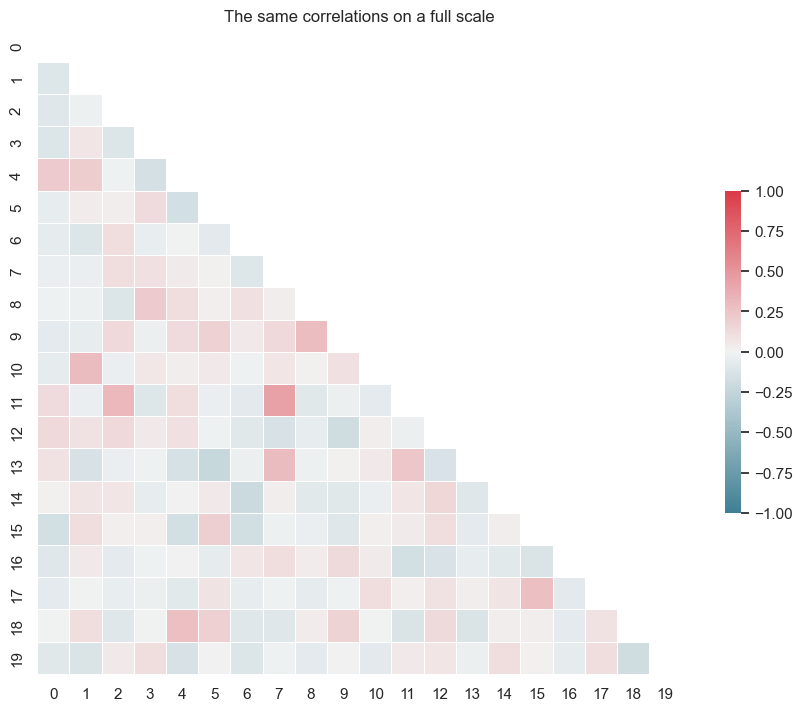

In [27]:
fig, ax = plt.subplots(figsize=(10, 7), layout="constrained")
sns.heatmap(corr, mask=mask, cmap=cmap, vmin=-1, vmax=1, center=0,
            square=True, linewidths=0.5, cbar_kws={'shrink': 0.5}, ax=ax)
ax.set_title('The same correlations on a full scale')
finish(fig, "task_heatmap")

**Tutor answer:** The correlation matrix is symmetric; the mask hides its redundant upper half and diagonal. The full scale makes modest correlations appear weaker. These independent simulated variables can show sample correlations by chance.

## 14 Orthographic globe with Blue Marble
Source 4.6 | 83–89 min

Run the worked example below.

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0000000000000002].


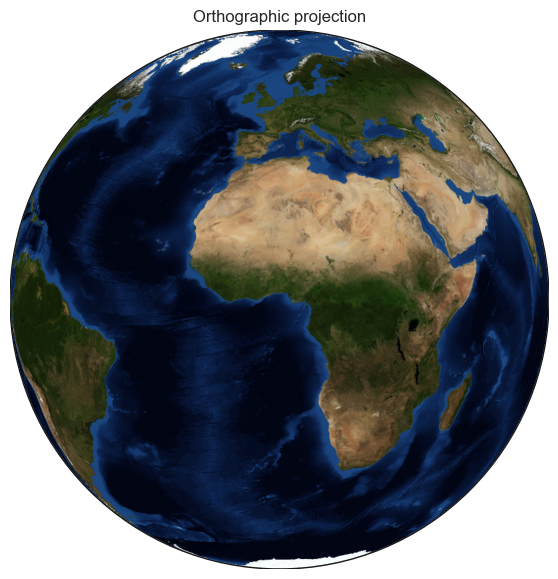

In [28]:
from mpl_toolkits.basemap import Basemap
fig, ax = plt.subplots(figsize=(7, 7))
globe = Basemap(projection='ortho', lat_0=5, lon_0=3, resolution=None, ax=ax)
globe.bluemarble(scale=0.5)
ax.set_title('Orthographic projection')
finish(fig, "globe")

### Your task
Change lon_0 to 90 and predict which part of the globe becomes visible.

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0000000000000002].


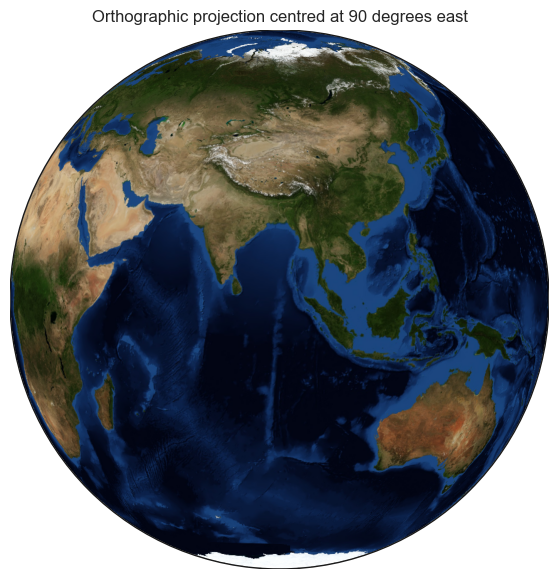

In [29]:
fig, ax = plt.subplots(figsize=(7, 7))
alternative = Basemap(projection='ortho', lat_0=5, lon_0=90, resolution=None, ax=ax)
alternative.bluemarble(scale=0.5)
ax.set_title('Orthographic projection centred at 90 degrees east')
finish(fig, "task_globe")

**Tutor answer:** The central longitude changes the visible hemisphere; it does not move any store. Blue Marble is a background image bundled with the map data.

## 15 Miller cylindrical projection
Source 4.6 | 89–95 min

Run the worked example below.

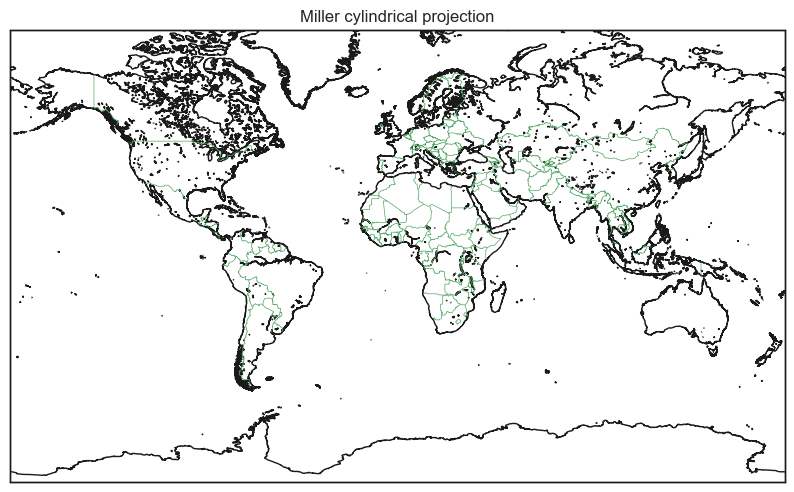

In [30]:
fig, ax = plt.subplots(figsize=(10, 7))
world = Basemap(projection='mill', llcrnrlat=-80, urcrnrlat=80,
                llcrnrlon=-180, urcrnrlon=180, resolution='i', ax=ax)
world.drawcoastlines()
world.drawcountries(color='g')
world.drawmapboundary(fill_color='white')
ax.set_title('Miller cylindrical projection')
finish(fig, "world")

### Your task
Explain the lower-left and upper-right bounds. Compare this map with the globe.

In [31]:
# Discuss the two projections.

**Tutor answer:** llcrnr and urcrnr specify the lower-left and upper-right corners. Projection changes the geographic representation; this map does not preserve all distances and areas.

## 16 Starbucks country ranking
Source 4.7 | 95–104 min

Run the worked example below.

       Brand  Store Number        Store Name Ownership Type  \
0  Starbucks  47370-257954     Meritxell, 96       Licensed   
1  Starbucks  22331-212325  Ajman Drive Thru       Licensed   
2  Starbucks  47089-256771         Dana Mall       Licensed   
3  Starbucks  22126-218024        Twofour 54       Licensed   
4  Starbucks  17127-178586      Al Ain Tower       Licensed   

                    Street Address              City State/Province Country  \
0                Av. Meritxell, 96  Andorra la Vella              7      AD   
1             1 Street 69, Al Jarf             Ajman             AJ      AE   
2     Sheikh Khalifa Bin Zayed St.             Ajman             AJ      AE   
3                  Al Salam Street         Abu Dhabi             AZ      AE   
4  Khaldiya Area, Abu Dhabi Island         Abu Dhabi             AZ      AE   

  Postcode Phone Number                 Timezone  Longitude  Latitude  
0    AD500    376818720  GMT+1:00 Europe/Andorra       1.53     42.51  
1 

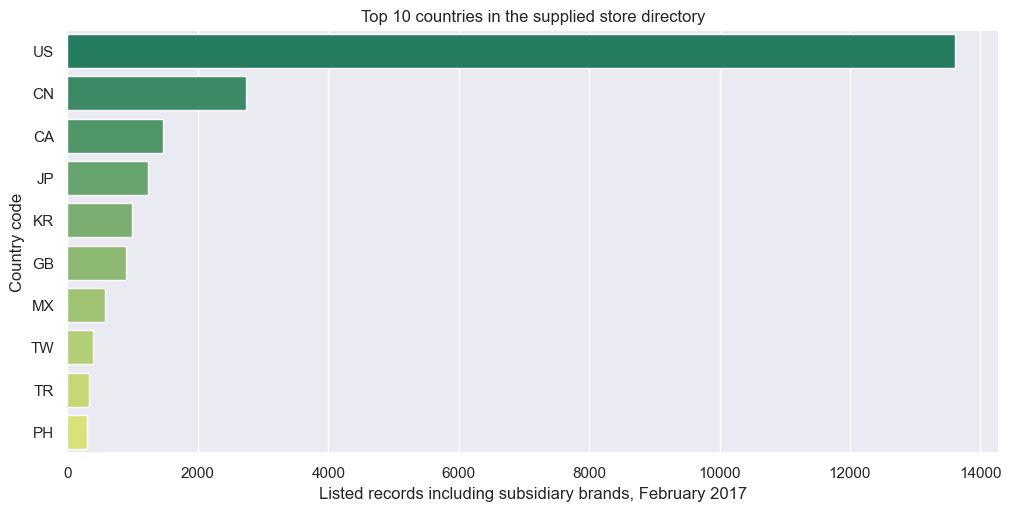

In [32]:
stores = pd.read_csv('Starbucks.csv')
print(stores.head())
print(stores.shape)
stores.info()
print(stores[['Longitude', 'Latitude']].isna().sum())
top10 = (stores['Country'].value_counts().head(10)
         .rename_axis('Country').reset_index(name='Stores'))
print(top10)
sns.set_theme(style='darkgrid')
fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
sns.barplot(data=top10, x='Stores', y='Country', hue='Country',
            palette='summer', legend=False, errorbar=None,
            order=top10['Country'].tolist(), ax=ax)
ax.set(title='Top 10 countries in the supplied store directory',
       xlabel='Listed records including subsidiary brands, February 2017', ylabel='Country code')
finish(fig, "country")

### Your task
Find the largest country count and the GB count. Check Brand values. Does the chart show present-day market share?

In [33]:
print(stores['Brand'].value_counts())
print("GB:", stores['Country'].eq('GB').sum())
print("Repeated Store Number:", stores['Store Number'].duplicated().sum())

Brand
Starbucks                25249
Teavana                    348
Evolution Fresh              2
Coffee House Holdings        1
Name: count, dtype: int64
GB: 901
Repeated Store Number: 1


**Tutor answer:** 25,600 rows, 13 columns. US 13,608; GB 901. The ranking counts all listed brands, matching the book. It is a historical directory, not current market share, sales or a verified census. One repeated Store Number needs investigation, not automatic deletion.

## 17 UK locations on a Cassini map
Source 4.7 | 104–111 min

Run the worked example below.

GB records: 901 mapped: 901


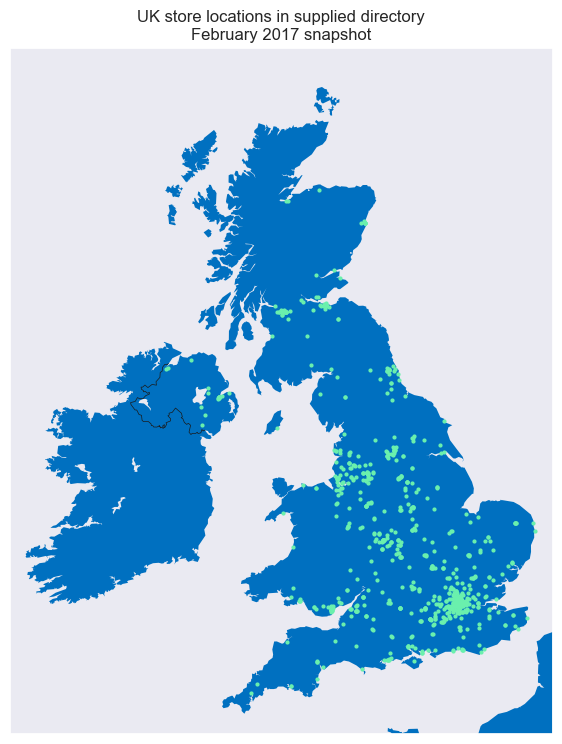

In [34]:
# GB is required by the book map but was not defined in its snippet.
GB = stores.loc[stores['Country'].eq('GB')].copy()
GB_map = GB.dropna(subset=['Longitude', 'Latitude']).copy()
print("GB records:", len(GB), "mapped:", len(GB_map))
fig, ax = plt.subplots(figsize=(7, 10))
uk = Basemap(llcrnrlon=-10.5, llcrnrlat=49.5, urcrnrlon=3.5,
             urcrnrlat=59.5, resolution='i', projection='cass',
             lon_0=-4.36, lat_0=54.7, ax=ax)
uk.drawcountries()
uk.fillcontinents(color='#0070C0')
map_x, map_y = uk(GB_map['Longitude'].to_numpy(), GB_map['Latitude'].to_numpy())
uk.plot(map_x, map_y, 'o', color='#6AF0AD', markersize=2)
ax.set_title('UK store locations in supplied directory\nFebruary 2017 snapshot')
finish(fig, "ukmap")

### Your task
Explain why longitude comes before latitude. Identify a visible concentration and state what extra data would be needed to choose a new location.

In [35]:
# Write a supported observation and one limitation.

**Tutor answer:** All 901 GB records have coordinates. Basemap converts longitude and latitude to projected x and y. Markers overlap, so visible dots need not equal store count. A concentration around London does not prove a profitable opportunity: demand, costs, competitors and current coverage are missing.

## 18 UK city ranking and export
Source 4.7 | 111–120 min

Run the worked example below.

In [36]:
# The chapter suggests a city ranking but leaves it as an exercise.
city_counts = GB['City'].value_counts().head(10)
print(city_counts)

City
London        195
Manchester     25
Edinburgh      20
Birmingham     17
Glasgow        17
Cardiff        14
Bristol        12
Liverpool      12
Sheffield      12
Belfast        11
Name: count, dtype: int64


### Your task
Create a horizontal bar chart for these ten recorded city labels. Add the snapshot date and save results/uk_city_ranking.png. Complete the exit questions in Markdown.

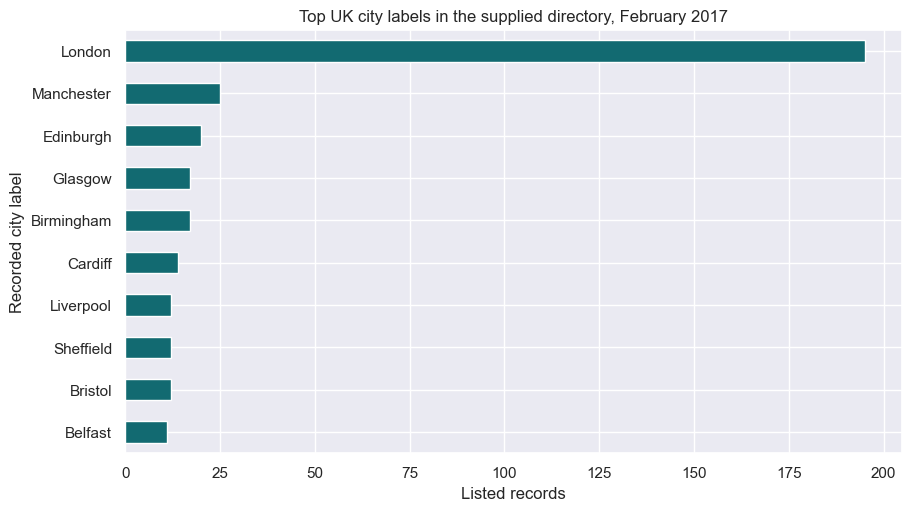

In [37]:
fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
city_counts.sort_values().plot.barh(ax=ax, color='#126A71')
ax.set(title='Top UK city labels in the supplied directory, February 2017',
       xlabel='Listed records', ylabel='Recorded city label')
fig.savefig(output_dir/'uk_city_ranking.png', dpi=200, bbox_inches='tight')
plt.show(); plt.close(fig)

**Tutor answer:** London 195, Manchester 25, Edinburgh 20. Birmingham and Glasgow tie at 17. These are exact recorded city labels, not harmonised metropolitan areas. Barh makes long labels easier to read. Save before closing the figure.

## Exit ticket and submission
Explain Figure versus Axes, histogram versus bar chart, why hiding fliers does not delete records, and why the map is not current network coverage. Save the completed notebook and your city chart. Restart the kernel and run all completed cells before submission.

## Reference patterns from the chapter
`ax.set_title()`, `ax.set_xlim()`, `ax.set_ylim()`, `ax.set_xlabel()` and `ax.set_ylabel()` change the named property. Set tick positions before labels; for example `ax.set_xticks([0, 5, 10], labels=['start', 'middle', 'end'])`. `fig.suptitle()` titles the whole Figure. `plt.subplot()` targets the current Figure; `fig.add_axes([left,bottom,width,height])` uses Figure-relative fractions.

Format examples: `o` circle, `*` star, `s` square, `x` cross; `-` solid, `--` dashed, `-.` dash-dot, `:` dotted. Full colour names and hex values can be passed using `color=`. Styles can be set with `plt.style.use()` or Seaborn themes.

pandas plotting: `df.plot()` line; `.plot.bar()` vertical bars; `.plot.barh()` horizontal bars; `.plot.hist()`, `.plot.box()`, `.plot.kde()`, `.plot.area()`, `.plot.scatter(x=..., y=...)` and `.plot.pie(y=...)`. Not every chart is appropriate for every table. `df.hist()` and `df.boxplot()` are separate convenience interfaces.

Basemap also provides contour, contourf, imshow, pcolor, pcolormesh, scatter, quiver, drawgreatcircle and barbs methods. Retain these as reference rather than new tasks today.

## Sources
Workshop 3.docx and Starbucks.csv supplied by the tutor. Iris sample: https://github.com/mwaskom/seaborn-data/blob/master/iris.csv (cached unchanged for offline teaching). Current API guidance checked 22 September 2026: https://matplotlib.org/stable/plot_types/index.html ; https://seaborn.pydata.org/api.html ; https://matplotlib.org/basemap/stable/users/installation.html .